# Etapa 3: evaluación de la red GCN-DeepGPD

Se prueban los modelos de O3 y SO2 (versión nueva de la red, con el MLP previo a la GCN, 7 capas GCN de 64 neuronas) entrenados con la **base corregida** (`data/datos_corregidos.csv`).
Para cada contaminante se compara la red contra la **GPD constante** (un solo $(\xi, \sigma)$ para todos los excesos de entrenamiento, `src/gpd_bfgs.py`).

Se calculan los criterios de evaluación de la Sección 3.7 del reporte:
1. Log-verosimilitud negativa (NLL) de los excesos: red vs GPD constante.
2. Puntaje de Brier de $P(Y>u+x \mid Y>u)$, comparado con predecir siempre la frecuencia de entrenamiento.
3. Calibración de las probabilidades (5 grupos).
4. Aciertos y falsas alarmas al emitir una alerta.

Se evalúa en los tres periodos: entrenamiento (2023-2024), validación (2025) y prueba (2026).
Al final del notebook están las gráficas para la presentación (se guardan en `figuras/`).

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import torch
from scipy.stats import genpareto
from sklearn.metrics import roc_auc_score


if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

from src.train import prepare_hourly_data, STATION_COORDS
from src.gpd_bfgs import fit_gpd_bfgs
from utils.model_architecture import Combiner
from utils.model_params import params_dict
from utils.haversine_distance import haversine_matrix
from utils.train_utils import predict

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", dispositivo)

Dispositivo: cuda



`u` es el umbral del modelo y `x` la distancia a la norma (`u + x`).

In [2]:
contaminantes = {
    "O3":  {"u": 63.0, "x": 27.0, "modelo": "models/model_o3.pth"},
    "SO2": {"u": 20.2, "x": 54.8, "modelo": "models/model_so2_hourly.pth"},
}

D = haversine_matrix(STATION_COORDS)

## Predicciones de la red en los tres periodos

`prepare_hourly_data` regresa (entrenamiento, 2025, 2026). Se usa la base corregida (dato observado donde existe, imputado solo donde faltaba). Cada dato trae los excesos observados `y` (en ppb, `NaN` donde no hubo exceso).
La red da un $(\xi, \sigma)$ por estación y día. Como `prepare_hourly_data` vuelve a guardar `models/scaler.pkl`, guardo una copia y
la regreso al final para no cambiar ese archivo.

In [3]:
with open("models/scaler.pkl", "rb") as f:
    scaler_original = f.read()

resultados_red = {}

for pol in contaminantes:
    u = contaminantes[pol]["u"]
    print("=====", pol, "=====")
    train, test, val = prepare_hourly_data("data/datos_corregidos.csv", pol, u)

    modelo = Combiner(
        ds_params=params_dict["ds_params"],
        gcn_params=params_dict["gcn_params"],
        graph_params=params_dict["graph_params"],
    )
    modelo.load_state_dict(torch.load(contaminantes[pol]["modelo"], map_location="cpu"))

    periodos = {"entrenamiento (2023-2024)": train,
                "validacion (2025)": test,
                "prueba (2026)": val}

    resultados_red[pol] = {}
    for nombre in periodos:
        datos = periodos[nombre]
        pred = predict(modelo, datos, D, device=dispositivo)     # (dias, 15 estaciones, 2)
        y = datos["y"].cpu().numpy()[:, 0, :, :]                 # (dias, 15, 24)
        resultados_red[pol][nombre] = {"y": y, "xi": pred[:, :, 0], "sigma": pred[:, :, 1]}
        print("  ", nombre, "-> dias:", y.shape[0], "| excesos observados:", int(np.sum(~np.isnan(y))))

with open("models/scaler.pkl", "wb") as f:
    f.write(scaler_original)

===== O3 =====


V torch.Size([730, 17, 15, 24])
S torch.Size([730, 1, 15, 24])
Y torch.Size([730, 1, 15, 24])
V torch.Size([364, 17, 15, 24])
S torch.Size([364, 1, 15, 24])
Y torch.Size([364, 1, 15, 24])
V torch.Size([211, 17, 15, 24])
S torch.Size([211, 1, 15, 24])
Y torch.Size([211, 1, 15, 24])


   entrenamiento (2023-2024) -> dias: 730 | excesos observados: 12343
   validacion (2025) -> dias: 364 | excesos observados: 8596
   prueba (2026) -> dias: 211 | excesos observados: 3919
===== SO2 =====


V torch.Size([730, 17, 15, 24])
S torch.Size([730, 1, 15, 24])
Y torch.Size([730, 1, 15, 24])
V torch.Size([364, 17, 15, 24])
S torch.Size([364, 1, 15, 24])
Y torch.Size([364, 1, 15, 24])
V torch.Size([211, 17, 15, 24])
S torch.Size([211, 1, 15, 24])
Y torch.Size([211, 1, 15, 24])
   entrenamiento (2023-2024) -> dias: 730 | excesos observados: 1421
   validacion (2025) -> dias: 364 | excesos observados: 1288
   prueba (2026) -> dias: 211 | excesos observados: 413


## GPD constante como referencia

Se ajusta una sola GPD a todos los excesos de entrenamiento con `fit_gpd_bfgs`

In [4]:
gpd_constante = {}

for pol in contaminantes:
    y_train = resultados_red[pol]["entrenamiento (2023-2024)"]["y"]
    ajuste = fit_gpd_bfgs(torch.tensor(y_train))
    gpd_constante[pol] = (ajuste["xi"], ajuste["sigma"])
    print(pol, "- excesos de entrenamiento:", ajuste["n_exceed"])
    print("   xi =", round(ajuste["xi"], 3), "(ee", round(ajuste["se_xi"], 3), ") | sigma =", round(ajuste["sigma"], 2), "(ee", round(ajuste["se_sigma"], 2), ")")

O3 - excesos de entrenamiento: 12343
   xi = -0.054 (ee 0.008 ) | sigma = 16.95 (ee 0.21 )
SO2 - excesos de entrenamiento: 1421
   xi = 0.303 (ee 0.037 ) | sigma = 10.21 (ee 0.46 )


## Métricas por contaminante y periodo

Cada hora con exceso es una observación. El evento es que el exceso llegue a la norma ($Y - u \geq x$).
La probabilidad de la red es la de su día y estación, la de la GPD constante es la misma para todos.
La "frecuencia" es predecir siempre la proporción de eventos del entrenamiento.

In [5]:
tabla = []
tabla_calibracion = []

for pol in contaminantes:
    x = contaminantes[pol]["x"]
    xi_c, sigma_c = gpd_constante[pol]

    # frecuencia de eventos en entrenamiento
    y_train = resultados_red[pol]["entrenamiento (2023-2024)"]["y"]
    y_train = y_train[~np.isnan(y_train)]
    tasa_train = np.mean(y_train >= x)

    print("==========", pol, "==========")
    print("Frecuencia de eventos en entrenamiento:", round(tasa_train, 4))

    for periodo in resultados_red[pol]:
        y = resultados_red[pol][periodo]["y"]
        hay_exceso = ~np.isnan(y)

        # parametros de la red para cada hora con exceso (se repite el de su dia y estacion)
        xi_todo = np.repeat(resultados_red[pol][periodo]["xi"][:, :, np.newaxis], 24, axis=2)
        sigma_todo = np.repeat(resultados_red[pol][periodo]["sigma"][:, :, np.newaxis], 24, axis=2)
        exc = y[hay_exceso]
        xi = xi_todo[hay_exceso]
        sigma = sigma_todo[hay_exceso]

        evento = (exc >= x).astype(int)
        n_exc = len(exc)
        n_eventos = int(evento.sum())

        # NLL (igual que la perdida del entrenamiento: el argumento del log se recorta en 1e-6)
        arg_red = 1 + xi * exc / sigma
        fuera_red = np.mean(arg_red <= 0)
        arg_red = np.clip(arg_red, 1e-6, None)
        nll_red = np.mean(np.log(sigma) + (1 + 1 / xi) * np.log(arg_red))

        arg_c = np.clip(1 + xi_c * exc / sigma_c, 1e-6, None)
        nll_c = np.mean(np.log(sigma_c) + (1 + 1 / xi_c) * np.log(arg_c))

        # probabilidades de superar la norma, dado que ya se supero u
        p_red = 1 - genpareto.cdf(x, c=xi, scale=sigma)
        p_c = 1 - genpareto.cdf(x, c=xi_c, scale=sigma_c)

        brier_red = np.mean((p_red - evento) ** 2)
        brier_c = np.mean((p_c - evento) ** 2)
        brier_freq = np.mean((tasa_train - evento) ** 2)

        if n_eventos > 0 and n_eventos < n_exc:
            auc = roc_auc_score(evento, p_red)
        else:
            auc = np.nan

        print("")
        print(periodo)
        print("  excesos:", n_exc, "| eventos (>= u + x):", n_eventos, "| tasa:", round(n_eventos / n_exc, 4))
        print("  NLL      red:", round(nll_red, 4), "| GPD constante:", round(nll_c, 4))
        if nll_red < nll_c:
            print("  -> la red tiene menor NLL que la GPD constante")
        else:
            print("  -> la red NO mejora la NLL de la GPD constante")
        print("  Brier    red:", round(brier_red, 4), "| GPD constante:", round(brier_c, 4), "| frecuencia:", round(brier_freq, 4))
        if brier_red < brier_freq:
            print("  -> el Brier de la red es menor que el de la frecuencia (mejora de", round(100 * (1 - brier_red / brier_freq), 1), "%)")
        else:
            print("  -> el Brier de la red NO es menor que el de la frecuencia")
        print("  AUC de la red:", round(auc, 3))
        print("  probabilidad media: red", round(p_red.mean(), 3), "| GPD constante", round(p_c, 3), "| observada", round(n_eventos / n_exc, 3))
        print("  excesos fuera del soporte de la red:", round(100 * fuera_red, 2), "%")

        tabla.append({"contaminante": pol, "periodo": periodo, "excesos": n_exc, "eventos": n_eventos,
                      "tasa_eventos": n_eventos / n_exc, "tasa_entrenamiento": tasa_train,
                      "nll_red": nll_red, "nll_gpd_constante": nll_c,
                      "brier_red": brier_red, "brier_gpd_constante": brier_c, "brier_frecuencia": brier_freq,
                      "auc_red": auc, "prob_media_red": p_red.mean(), "prob_gpd_constante": p_c})

        # calibracion: 5 grupos segun la probabilidad de la red
        datos_cal = pd.DataFrame({"p": p_red, "evento": evento})
        datos_cal["grupo"] = pd.qcut(datos_cal["p"], 5, labels=False, duplicates="drop") + 1
        cal = datos_cal.groupby("grupo").agg(n=("evento", "size"), prob_predicha=("p", "mean"), frec_observada=("evento", "mean"))
        cal = cal.reset_index()
        cal.insert(0, "periodo", periodo)
        cal.insert(0, "contaminante", pol)
        tabla_calibracion.append(cal)

========== O3 ==========
Frecuencia de eventos en entrenamiento: 0.1872

entrenamiento (2023-2024)
  excesos: 12343 | eventos (>= u + x): 2311 | tasa: 0.1872
  NLL      red: 3.7563 | GPD constante: 3.7764
  -> la red tiene menor NLL que la GPD constante
  Brier    red: 0.1474 | GPD constante: 0.1522 | frecuencia: 0.1522
  -> el Brier de la red es menor que el de la frecuencia (mejora de 3.2 %)
  AUC de la red: 0.643
  probabilidad media: red 0.182 | GPD constante 0.189 | observada 0.187
  excesos fuera del soporte de la red: 0.0 %

validacion (2025)
  excesos: 8596 | eventos (>= u + x): 1742 | tasa: 0.2027
  NLL      red: 3.795 | GPD constante: 3.8046
  -> la red tiene menor NLL que la GPD constante
  Brier    red: 0.158 | GPD constante: 0.1618 | frecuencia: 0.1618
  -> el Brier de la red es menor que el de la frecuencia (mejora de 2.3 %)
  AUC de la red: 0.628
  probabilidad media: red 0.169 | GPD constante 0.189 | observada 0.203
  excesos fuera del soporte de la red: 0.0 %

prueba (

## Calibración

Si la red dice 20 %, el evento debería ocurrir cerca del 20 % de las veces.

In [6]:
calibracion = pd.concat(tabla_calibracion, ignore_index=True)

for pol in contaminantes:
    for periodo in resultados_red[pol]:
        print(pol, "-", periodo)
        parte = calibracion[(calibracion["contaminante"] == pol) & (calibracion["periodo"] == periodo)]
        print(parte[["grupo", "n", "prob_predicha", "frec_observada"]].round(3).to_string(index=False))
        print("")

O3 - entrenamiento (2023-2024)
 grupo    n  prob_predicha  frec_observada
     1 2471          0.121           0.079
     2 2467          0.156           0.144
     3 2472          0.179           0.190
     4 2470          0.205           0.223
     5 2463          0.250           0.301

O3 - validacion (2025)
 grupo    n  prob_predicha  frec_observada
     1 1726          0.113           0.117
     2 1714          0.145           0.151
     3 1719          0.166           0.201
     4 1720          0.191           0.228
     5 1717          0.231           0.316

O3 - prueba (2026)
 grupo   n  prob_predicha  frec_observada
     1 784          0.121           0.171
     2 785          0.148           0.167
     3 784          0.167           0.218
     4 784          0.188           0.237
     5 782          0.222           0.269

SO2 - entrenamiento (2023-2024)
 grupo   n  prob_predicha  frec_observada
     1 285          0.013           0.004
     2 284          0.032           0.01

## Alertas: aciertos y falsas alarmas

Condicionado a que ya se superó $u$, se emite una alerta cuando la probabilidad de la red es mayor o igual a $\tau$.
Probamos dos valores: la frecuencia de eventos del entrenamiento y el percentil 80 de las probabilidades de entrenamiento (se alerta a la quinta parte de las horas de mayor riesgo).

In [7]:
tabla_alertas = []

for pol in contaminantes:
    x = contaminantes[pol]["x"]
    for fila in tabla:
        if fila["contaminante"] == pol:
            tasa_train = fila["tasa_entrenamiento"]

    # segundo umbral: percentil 80 de las probabilidades de entrenamiento
    y_t = resultados_red[pol]["entrenamiento (2023-2024)"]["y"]
    hay_t = ~np.isnan(y_t)
    xi_t = np.repeat(resultados_red[pol]["entrenamiento (2023-2024)"]["xi"][:, :, np.newaxis], 24, axis=2)
    sigma_t = np.repeat(resultados_red[pol]["entrenamiento (2023-2024)"]["sigma"][:, :, np.newaxis], 24, axis=2)
    p_train = 1 - genpareto.cdf(x, c=xi_t[hay_t], scale=sigma_t[hay_t])
    tau_alto = np.percentile(p_train, 80)

    for periodo in resultados_red[pol]:
        y = resultados_red[pol][periodo]["y"]
        hay_exceso = ~np.isnan(y)
        xi_todo = np.repeat(resultados_red[pol][periodo]["xi"][:, :, np.newaxis], 24, axis=2)
        sigma_todo = np.repeat(resultados_red[pol][periodo]["sigma"][:, :, np.newaxis], 24, axis=2)
        exc = y[hay_exceso]
        p_red = 1 - genpareto.cdf(x, c=xi_todo[hay_exceso], scale=sigma_todo[hay_exceso])
        evento = (exc >= x)

        print(pol, "-", periodo, "(eventos:", int(evento.sum()), ")")
        for tau in [tasa_train, tau_alto]:
            alerta = p_red >= tau
            aciertos = np.sum(alerta & evento) / np.sum(evento) if np.sum(evento) > 0 else np.nan
            falsas = np.sum(alerta & ~evento) / np.sum(~evento)
            precision = np.sum(alerta & evento) / np.sum(alerta) if np.sum(alerta) > 0 else np.nan
            print("   tau =", round(tau, 3), "| alertas:", int(alerta.sum()), "| aciertos:", round(aciertos, 3),
                  "| falsas alarmas:", round(falsas, 3), "| precision:", round(precision, 3))
            tabla_alertas.append({"contaminante": pol, "periodo": periodo, "tau": tau, "alertas": int(alerta.sum()),
                                  "aciertos": aciertos, "falsas_alarmas": falsas, "precision": precision})

O3 - entrenamiento (2023-2024) (eventos: 2311 )
   tau = 0.187 | alertas: 5376 | aciertos: 0.601 | falsas alarmas: 0.398 | precision: 0.258
   tau = 0.221 | alertas: 2470 | aciertos: 0.321 | falsas alarmas: 0.172 | precision: 0.3
O3 - validacion (2025) (eventos: 1742 )
   tau = 0.187 | alertas: 2833 | aciertos: 0.46 | falsas alarmas: 0.296 | precision: 0.283
   tau = 0.221 | alertas: 1021 | aciertos: 0.226 | falsas alarmas: 0.092 | precision: 0.385
O3 - prueba (2026) (eventos: 832 )
   tau = 0.187 | alertas: 1218 | aciertos: 0.374 | falsas alarmas: 0.294 | precision: 0.255
   tau = 0.221 | alertas: 363 | aciertos: 0.138 | falsas alarmas: 0.08 | precision: 0.317
SO2 - entrenamiento (2023-2024) (eventos: 61 )
   tau = 0.043 | alertas: 744 | aciertos: 0.918 | falsas alarmas: 0.506 | precision: 0.075
   tau = 0.081 | alertas: 286 | aciertos: 0.246 | falsas alarmas: 0.199 | precision: 0.052
SO2 - validacion (2025) (eventos: 69 )
   tau = 0.043 | alertas: 636 | aciertos: 0.754 | falsas alarm

## Resumen y exportación

Se guardan las métricas, la calibración y las alertas en archivos `.csv` dentro de `data/`.

In [8]:
tabla = pd.DataFrame(tabla)
tabla_alertas = pd.DataFrame(tabla_alertas)

print("Resumen de metricas")
print(tabla[["contaminante", "periodo", "excesos", "eventos", "nll_red", "nll_gpd_constante",
             "brier_red", "brier_frecuencia", "auc_red"]].round(3).to_string(index=False))

tabla.to_csv("data/resultados_metricas_red_nueva.csv", index=False)
calibracion.to_csv("data/resultados_calibracion_red_nueva.csv", index=False)
tabla_alertas.to_csv("data/resultados_alertas_red_nueva.csv", index=False)

Resumen de metricas
contaminante                   periodo  excesos  eventos  nll_red  nll_gpd_constante  brier_red  brier_frecuencia  auc_red
          O3 entrenamiento (2023-2024)    12343     2311    3.756              3.776      0.147             0.152    0.643
          O3         validacion (2025)     8596     1742    3.795              3.805      0.158             0.162    0.628
          O3             prueba (2026)     3919      832    3.822              3.818      0.167             0.168    0.570
         SO2 entrenamiento (2023-2024)     1421       61    3.612              3.626      0.040             0.041    0.665
         SO2         validacion (2025)     1288       69    3.744              3.728      0.050             0.051    0.702
         SO2             prueba (2026)      413       12    3.504              3.508      0.028             0.028    0.707


## Gráficas para la presentación

Se guardan en `figuras/` con el nombre `fig_red_*.png`. Primero se arma una tabla por periodo con cada hora que tuvo exceso:
su fecha, su estación, la probabilidad que dio la red y si fue evento (el exceso llegó a la norma).

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})

nombres_est = ["CE", "NE", "NE2", "NE3", "NO", "NO2", "NO3", "NTE", "NTE2", "SE", "SE2", "SE3", "SO", "SO2", "SUR"]
inicio = {"entrenamiento (2023-2024)": "2023-01-02", "validacion (2025)": "2025-01-02", "prueba (2026)": "2026-01-02"}
color_pol = {"O3": "#1f77b4", "SO2": "#d95f02"}
nombre_periodo = {"validacion (2025)": "Validación 2025", "prueba (2026)": "Prueba 2026"}

horas_exceso = {}

for pol in contaminantes:
    x = contaminantes[pol]["x"]
    horas_exceso[pol] = {}
    for periodo in resultados_red[pol]:
        y = resultados_red[pol][periodo]["y"]
        dia, est, hora = np.indices(y.shape)
        hay_exceso = ~np.isnan(y)

        xi_todo = np.repeat(resultados_red[pol][periodo]["xi"][:, :, np.newaxis], 24, axis=2)
        sigma_todo = np.repeat(resultados_red[pol][periodo]["sigma"][:, :, np.newaxis], 24, axis=2)
        p = 1 - genpareto.cdf(x, c=xi_todo[hay_exceso], scale=sigma_todo[hay_exceso])

        fecha = pd.Timestamp(inicio[periodo]) + pd.to_timedelta(dia[hay_exceso], unit="D")
        horas_exceso[pol][periodo] = pd.DataFrame({"fecha": fecha, "estacion": est[hay_exceso],
                                                   "p": p, "evento": (y[hay_exceso] >= x).astype(int)})

print(horas_exceso["O3"]["prueba (2026)"].head())

       fecha  estacion         p  evento
0 2026-01-02         3  0.131612       0
1 2026-01-02         3  0.131612       0
2 2026-01-02        11  0.148574       0
3 2026-01-02        14  0.200803       0
4 2026-01-03        13  0.199887       0


### 1. Mejora del Brier de la red

Se compara el Brier de la red con el de predecir siempre la frecuencia de entrenamiento (la GPD constante da prácticamente lo mismo). Mientras más alto, mejor.

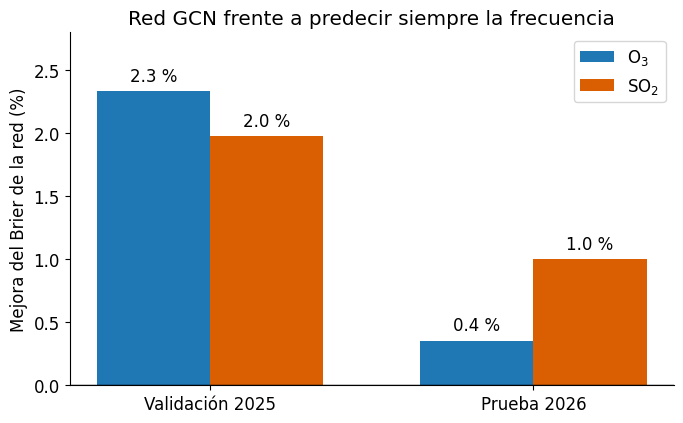

In [10]:
fig, eje = plt.subplots(figsize=(7, 4.4))

ancho = 0.35
for k, pol in enumerate(contaminantes):
    parte = tabla[(tabla["contaminante"] == pol) & (tabla["periodo"] != "entrenamiento (2023-2024)")]
    mejora = 100 * (1 - parte["brier_red"].values / parte["brier_frecuencia"].values)
    posiciones = np.arange(len(parte)) + (k - 0.5) * ancho
    eje.bar(posiciones, mejora, ancho, label=pol.replace("O3", "O$_3$").replace("SO2", "SO$_2$"), color=color_pol[pol])
    for i in range(len(parte)):
        eje.text(posiciones[i], mejora[i] + 0.05, f"{mejora[i]:.1f} %", ha="center", va="bottom")

eje.axhline(0, color="black", lw=1)
eje.set_ylim(0, 2.8)
eje.set_xticks(np.arange(2))
eje.set_xticklabels(["Validación 2025", "Prueba 2026"])
eje.set_ylabel("Mejora del Brier de la red (%)")
eje.set_title("Red GCN frente a predecir siempre la frecuencia")
eje.legend()

fig.tight_layout()
fig.savefig("figuras/fig_red_brier.png", dpi=200, bbox_inches="tight")
plt.show()

### 2. Calibración

Si los puntos caen sobre la diagonal, la probabilidad que da la red es la frecuencia real.

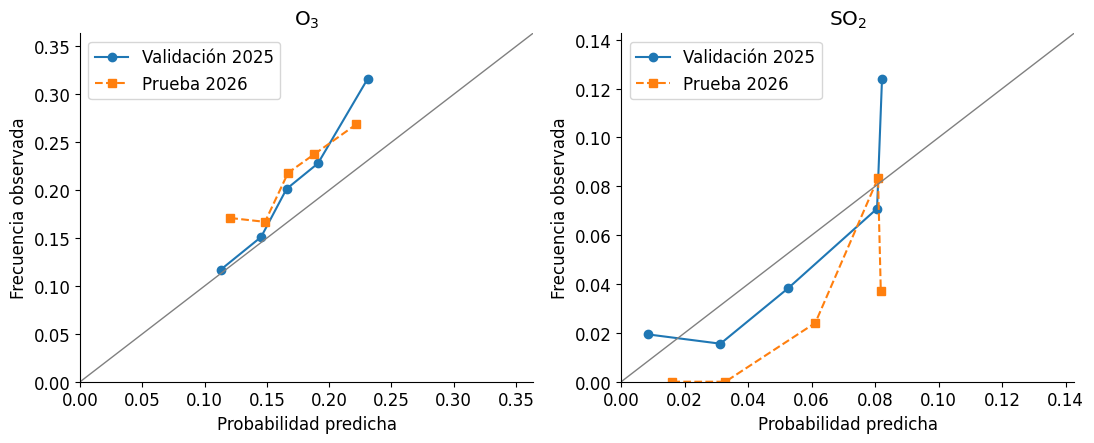

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.6))

for eje, pol in zip(ejes, contaminantes):
    for periodo, marca in [("validacion (2025)", "o-"), ("prueba (2026)", "s--")]:
        parte = calibracion[(calibracion["contaminante"] == pol) & (calibracion["periodo"] == periodo)]
        eje.plot(parte["prob_predicha"], parte["frec_observada"], marca, label=nombre_periodo[periodo])
    tope = 1.15 * calibracion[calibracion["contaminante"] == pol][["prob_predicha", "frec_observada"]].values.max()
    eje.plot([0, tope], [0, tope], color="gray", lw=1)
    eje.set_xlim(0, tope)
    eje.set_ylim(0, tope)
    eje.set_xlabel("Probabilidad predicha")
    eje.set_ylabel("Frecuencia observada")
    eje.set_title(pol.replace("O3", "O$_3$").replace("SO2", "SO$_2$"))
    eje.legend()

fig.tight_layout()
fig.savefig("figuras/fig_red_calibracion.png", dpi=200, bbox_inches="tight")
plt.show()

### 3. Curva ROC: aciertos contra falsas alarmas

Cada punto de la curva es un umbral de alerta distinto. La diagonal es el azar.

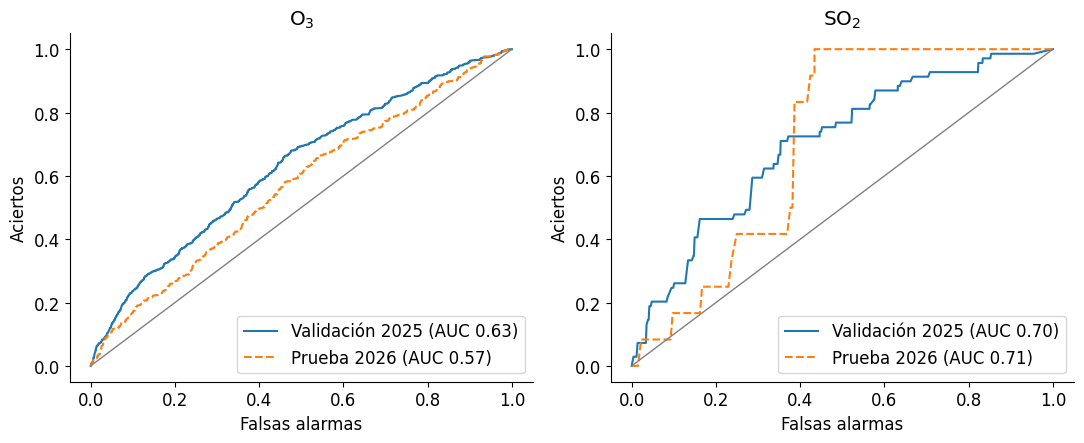

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.6))

for eje, pol in zip(ejes, contaminantes):
    for periodo, estilo in [("validacion (2025)", "-"), ("prueba (2026)", "--")]:
        datos = horas_exceso[pol][periodo]
        falsas, aciertos, _ = roc_curve(datos["evento"], datos["p"])
        auc = roc_auc_score(datos["evento"], datos["p"])
        eje.plot(falsas, aciertos, estilo, label=nombre_periodo[periodo] + f" (AUC {auc:.2f})")
    eje.plot([0, 1], [0, 1], color="gray", lw=1)
    eje.set_xlabel("Falsas alarmas")
    eje.set_ylabel("Aciertos")
    eje.set_title(pol.replace("O3", "O$_3$").replace("SO2", "SO$_2$"))
    eje.legend(loc="lower right")

fig.tight_layout()
fig.savefig("figuras/fig_red_roc.png", dpi=200, bbox_inches="tight")
plt.show()

### 4. Probabilidad de la red a lo largo del tiempo

Por mes (2025 y 2026): probabilidad media que da la red contra la frecuencia de eventos observada.

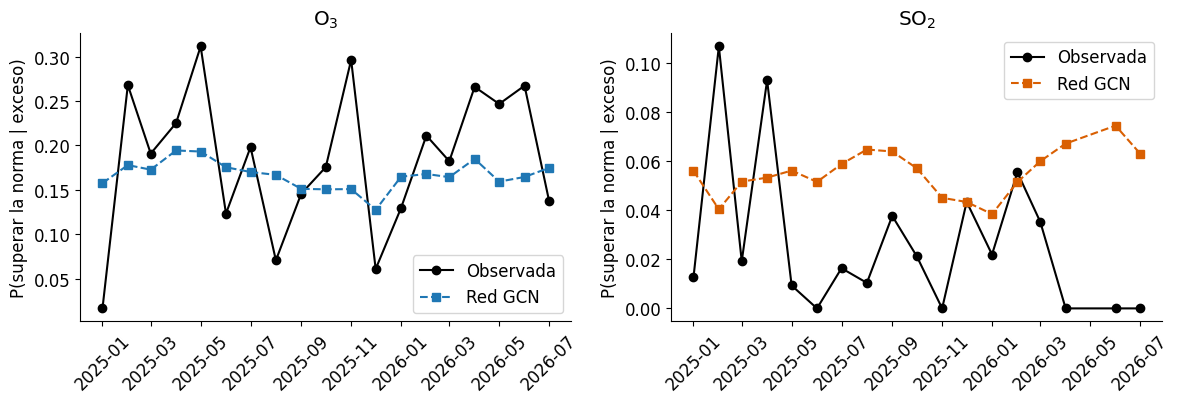

In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))

for eje, pol in zip(ejes, contaminantes):
    datos = pd.concat([horas_exceso[pol]["validacion (2025)"], horas_exceso[pol]["prueba (2026)"]])
    datos["mes"] = datos["fecha"].dt.to_period("M").dt.to_timestamp()
    por_mes = datos.groupby("mes").agg(prob_red=("p", "mean"), observada=("evento", "mean"), n=("evento", "size"))
    por_mes = por_mes[por_mes["n"] >= 20]
    eje.plot(por_mes.index, por_mes["observada"], "o-", color="black", label="Observada")
    eje.plot(por_mes.index, por_mes["prob_red"], "s--", color=color_pol[pol], label="Red GCN")
    eje.set_title(pol.replace("O3", "O$_3$").replace("SO2", "SO$_2$"))
    eje.set_ylabel("P(superar la norma | exceso)")
    eje.tick_params(axis="x", rotation=45)
    eje.legend()

fig.tight_layout()
fig.savefig("figuras/fig_red_mensual.png", dpi=200, bbox_inches="tight")
plt.show()

### 5. Mapa por estación

Probabilidad media de la red y frecuencia observada de eventos en cada estación (2025 y 2026).

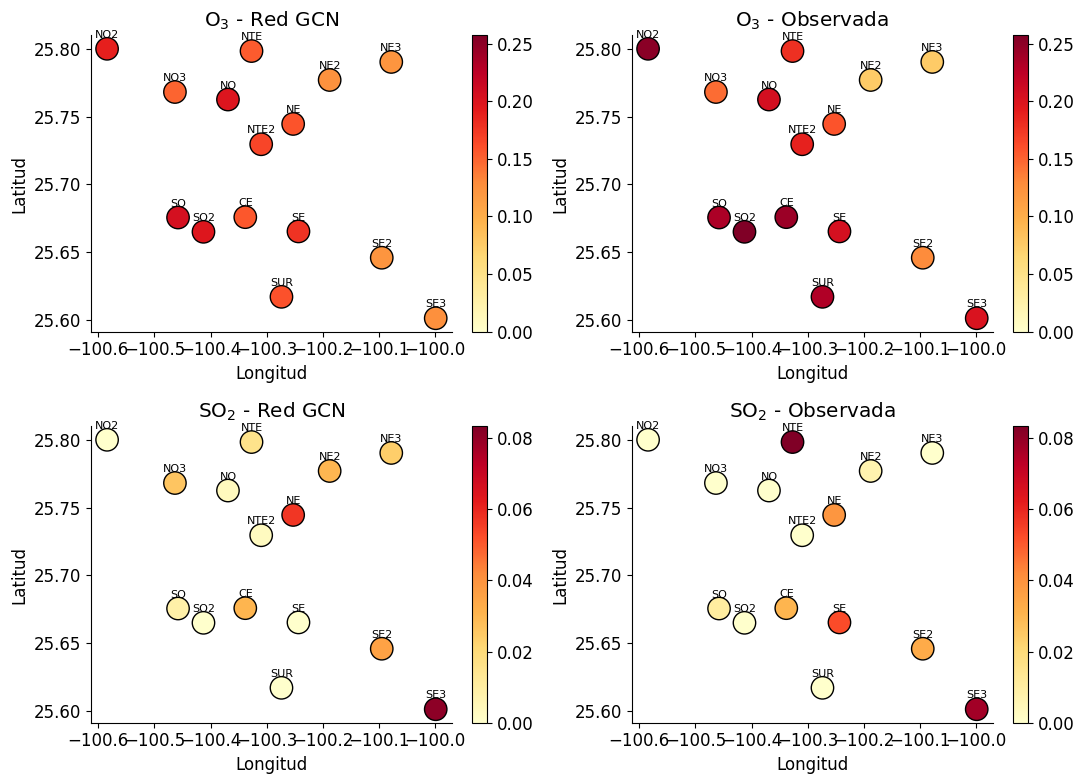

In [14]:
coords = STATION_COORDS.numpy()

fig, ejes = plt.subplots(2, 2, figsize=(11, 8))

for fila, pol in enumerate(contaminantes):
    datos = pd.concat([horas_exceso[pol]["validacion (2025)"], horas_exceso[pol]["prueba (2026)"]])
    por_est = datos.groupby("estacion").agg(prob_red=("p", "mean"), observada=("evento", "mean"))
    por_est = por_est.reindex(range(15))
    vmax = max(por_est["prob_red"].max(), por_est["observada"].max())

    for col, (columna, titulo) in enumerate([("prob_red", "Red GCN"), ("observada", "Observada")]):
        eje = ejes[fila, col]
        puntos = eje.scatter(coords[:, 1], coords[:, 0], c=por_est[columna], s=260, cmap="YlOrRd", vmin=0, vmax=vmax, edgecolor="black")
        for i in range(15):
            eje.text(coords[i, 1], coords[i, 0] + 0.008, nombres_est[i], ha="center", fontsize=8)
        eje.set_title(pol.replace("O3", "O$_3$").replace("SO2", "SO$_2$") + " - " + titulo)
        eje.set_xlabel("Longitud")
        eje.set_ylabel("Latitud")
        fig.colorbar(puntos, ax=eje, fraction=0.04)

fig.tight_layout()
fig.savefig("figuras/fig_red_mapa.png", dpi=200, bbox_inches="tight")
plt.show()